# YOLO11n — phát hiện và phân loại độ chín quả

Hai lớp ripe/unripe, chưa nhận diện bệnh quả. Huấn luyện bằng hosted GPU runtime Colab.
Đóng gói bằng `scripts/package-colab.ps1`, upload source ZIP và `tomato-ripeness-v4.zip`
vào `MyDrive/aiot-plant-care/`. Chọn runtime Python 3.12 + GPU; cho phép mount Drive.
Train đầy đủ/Test mặc định tắt. Smoke chỉ kiểm tra pipeline, không chứng minh chất lượng.


In [1]:
from pathlib import Path
import os
import sys
import hashlib
import zipfile
import importlib

if sys.platform != "linux":
    raise RuntimeError("Chọn hosted runtime Google Colab; không dùng kernel Windows/local.")
try:
    from google.colab import drive
except ImportError as error:
    raise RuntimeError("Notebook yêu cầu hosted runtime Google Colab.") from error
drive.mount("/content/drive")
DRIVE_ROOT = Path(os.getenv("COLAB_DRIVE_ROOT", "/content/drive/MyDrive/aiot-plant-care"))
SOURCE_ZIP = DRIVE_ROOT / "aiot-ml-colab.zip"
if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f"Upload ZIP mã nguồn trước: {SOURCE_ZIP}")
with SOURCE_ZIP.open("rb") as stream:
    source_hash = hashlib.file_digest(stream, "sha256").hexdigest()
ML_ROOT = Path("/content") / f"aiot-ml-{source_hash[:12]}"
ready = ML_ROOT / ".ready"
if not ready.exists():
    if ML_ROOT.exists() and any(ML_ROOT.iterdir()):
        raise RuntimeError("Source giải nén dở; dùng runtime mới, không trộn source.")
    with zipfile.ZipFile(SOURCE_ZIP) as archive:
        if sum(item.file_size for item in archive.infolist()) > 50 * 1024**2:
            raise ValueError("Source ZIP quá lớn; không đóng kèm dataset/weights.")
        for item in archive.infolist():
            target = (ML_ROOT / item.filename).resolve()
            if (not target.is_relative_to(ML_ROOT) or chr(92) in item.orig_filename
                    or (item.external_attr >> 16) & 0o170000 == 0o120000):
                raise ValueError("Source ZIP có đường dẫn không hợp lệ hoặc symlink")
        archive.extractall(ML_ROOT)
    ready.write_text(source_hash, encoding="utf-8")
sys.path.insert(0, str(ML_ROOT))
if "colab_runtime" in sys.modules and Path(sys.modules["colab_runtime"].__file__).resolve() != ML_ROOT / "colab_runtime.py":
    raise RuntimeError("Source ZIP changed: restart session before continuing.")
colab_runtime = importlib.import_module("colab_runtime")
prepare_runtime = colab_runtime.prepare_runtime
extract_zip_once = colab_runtime.extract_zip_once

INSTALL_DEPS = True  # Nếu thư viện đã đúng lock, không cài lại.
RUNTIME_INFO = prepare_runtime(ML_ROOT, require_gpu=True, install=INSTALL_DEPS)
CODE_ROOT = ML_ROOT / "fruit-health"
sys.path.insert(0, str(CODE_ROOT))
os.chdir(CODE_ROOT)
print("Kernel Colab:", sys.executable, "| Source SHA256:", source_hash)

RUNS_ROOT = Path(os.getenv("FRUIT_OUTPUT_ROOT", str(DRIVE_ROOT / "fruit-runs")))
RUNS_ROOT.mkdir(parents=True, exist_ok=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.12.13",
  "torch": "2.11.0+cu128",
  "torchvision": "0.26.0+cu128",
  "cuda": "12.8",
  "device": "Tesla T4"
}
Kernel Colab: /usr/bin/python3 | Source SHA256: 5aeff8959d22dca2002dc7fce54b37ae19e2f9943fed5a5d9a1909bc453e0695


## Môi trường Colab

Bootstrap cài lock bổ sung bằng `--no-deps`, giữ Torch/CUDA của runtime.
Nếu yêu cầu restart session, restart rồi chạy lại từ đầu. Không cài lock Windows.
Batch 16, workers 2 là cấu hình khởi đầu, giảm batch khi OOM.


In [2]:
import importlib.metadata as metadata
import torch
import torchvision

if not torch.cuda.is_available():
    raise RuntimeError("Chọn GPU runtime Colab rồi chạy lại bootstrap")
if metadata.version("ultralytics") != "8.3.203":
    raise RuntimeError("Cần Ultralytics đúng requirements-colab.lock")
print({"torch": torch.__version__, "torchvision": torchvision.__version__,
       "cuda": torch.version.cuda, "gpu": torch.cuda.get_device_name(0),
       "vram_gib": round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2)})
torch.set_num_threads(2)


{'torch': '2.11.0+cu128', 'torchvision': '0.26.0+cu128', 'cuda': '12.8', 'gpu': 'Tesla T4', 'vram_gib': 14.56}


## Dataset v4

[Tomato Ripeness v4](https://universe.roboflow.com/uni-zkvyc/tomato-ripeness-um0yl/dataset/4), CC BY 4.0.
Mặc định giải nén ZIP từ Drive vào `/content`; raw polygon được chuyển sang bbox trong bản riêng.
Tùy chọn `roboflow` lấy key từ Colab Secrets `ROBOFLOW_API_KEY`, không ghi key vào notebook.


In [3]:
from fruit_training.download import download_roboflow

DATA_SOURCE = "drive_zip"
RAW_DEST = Path("/content/aiot-data/tomato-ripeness-v4")
if DATA_SOURCE == "drive_zip":
    extracted = extract_zip_once(DRIVE_ROOT / "tomato-ripeness-v4.zip", RAW_DEST)
    candidates = list(extracted.rglob("data.yaml"))
    if len(candidates) != 1:
        raise ValueError("ZIP cần đúng một data.yaml")
    DATA_ROOT = candidates[0].parent
elif DATA_SOURCE == "roboflow":
    from google.colab import userdata
    existing = list(RAW_DEST.rglob("data.yaml")) if RAW_DEST.exists() else []
    if len(existing) == 1:
        DATA_ROOT = existing[0].parent  # Audit sẽ kiểm tra dữ liệu trước khi train.
    else:
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
        DATA_ROOT = download_roboflow(RAW_DEST)
else:
    raise ValueError("DATA_SOURCE phải là drive_zip hoặc roboflow")
print("Dataset:", DATA_ROOT)


Dataset: /content/aiot-data/tomato-ripeness-v4/tomato-ripeness-v4


## Audit nhãn, ảnh trùng và rò rỉ giữa các tập
Giữ split nguồn; nhóm ảnh theo SHA/pixel, tên ảnh trước `.rf.`, pHash và CSV group tùy chọn.
Nhóm giao nhiều tập được giữ phía **Test > Validation > Train**, loại phía còn lại.
Ảnh trùng pixel nhưng nhãn khác nhau được cách ly. Không đưa ảnh Test trở lại Train.
pHash/tên ảnh là heuristic, có thể gom nhầm; cũng không đảm bảo phát hiện mọi ảnh cùng cây/video.
Rà soát nhóm lớn, ảnh gần trùng và metadata cảnh trước thí nghiệm đầy đủ.
`groups.csv` nếu có: hai cột `path,group_id`; path tương đối từ DATA_ROOT, dấu `/`.
Audit có thể mất vài phút; không dùng kết quả Test để điều chỉnh rule này.


In [4]:
import json
from datetime import datetime, timezone
import pandas as pd
from fruit_training.data import (audit_dataset, prepare_dataset, smoke_subset,
                                 verify_prepared, manifest_fingerprint)

SESSION = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
SEED = int(os.getenv("FRUIT_SEED", "42"))
GROUPS_CSV = None  # ví dụ DATA_ROOT / "groups.csv", do bạn xác nhận cảnh/cây/video
records, audit = audit_dataset(DATA_ROOT, RUNS_ROOT / f"audit-{SESSION}", groups_csv=GROUPS_CSV)
display(pd.DataFrame({"raw_images": audit["inventory"], "clean_images": audit["clean_split_images"],
                      "negative_images": audit["negative_images"]}))
display(pd.DataFrame(audit["class_box_counts"]).T)
print("Ảnh hợp lệ:", audit["valid_images"], "Polygon:", audit["raw_polygon_count"])
print("Loại/cách ly:", pd.Series([row["reason"] for row in audit["excluded"]]).value_counts().to_dict())
print("Nhóm lớn nhất:", max((len(g["paths"]) for g in audit["groups"]), default=1))
display(pd.DataFrame(sorted(audit["groups"], key=lambda g: -len(g["paths"]))[:10]))


,raw_images,clean_images,negative_images
train,5466,1414,0
val,1682,860,0
test,1261,1254,0


,ripe,unripe
train,2045,1105
val,1078,818
test,1461,1424


Ảnh hợp lệ: 8409 Polygon: 17875
Loại/cách ly: {'cross_split_group': 4831, 'annotation_conflict': 50}
Nhóm lớn nhất: 570


,group_id,owner,paths,original_splits
0,c4a5d0ee0aad3f501277827a85da63567a184a77dc0408...,test,[train/images/232_jpg.rf.0bb9cb19cba75a04d079c...,"[test, train, val]"
1,ad68c555f68789820dfc6d32cbfc5f4db1bcf6abcae289...,test,[train/images/u-102-_png.rf.88f9bc1124f57539ac...,"[test, train, val]"
2,9771935d3f1be41a68dcea5dc396a468a4bf8adcad5115...,val,[train/images/IMG20230715142242_jpg.rf.95a2927...,"[train, val]"
3,2a6ce6d3a3e716edb4f1e2ea9b9c23cc99ec376ede38df...,test,[train/images/images-2-_jpeg.rf.0622c84d6a1d01...,"[test, train, val]"
4,3f04cb5bcf68091b44be1d8256bb51e1c91fba6eb083fe...,test,[train/images/u-14-_png.rf.06623905c9e161e8a5f...,"[test, train, val]"
5,4d90b01e0cd17617540f21e17bf1f9b000d5c81d5872ac...,test,[train/images/unripe-107-_jpg.rf.43219d0ab7b37...,"[test, train, val]"
6,2bd897b2b11c49597d473603a992dc56c3d26809d57e84...,test,[train/images/Screenshot-2025-01-05-034534_png...,"[test, train, val]"
7,e91a59e49f674ff838763d3a22bffd4b728fe555743167...,test,[train/images/Screenshot-2025-01-05-034143_png...,"[test, train, val]"
8,1114a8cff0f180db1a20665e2bdf1483c5781de4352d33...,test,[train/images/Screenshot-2025-01-05-034206_png...,"[test, train, val]"
9,072bdf306439715576ad1f912c3fe3e5d3a2ef8f6982f4...,test,[train/images/Screenshot-2025-01-05-034425_png...,"[test, train, val]"


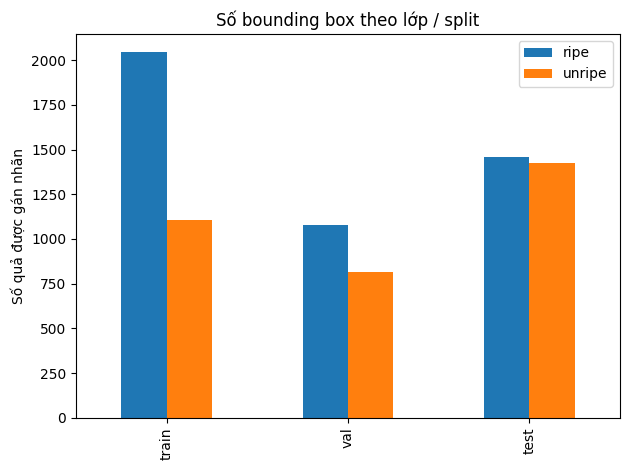

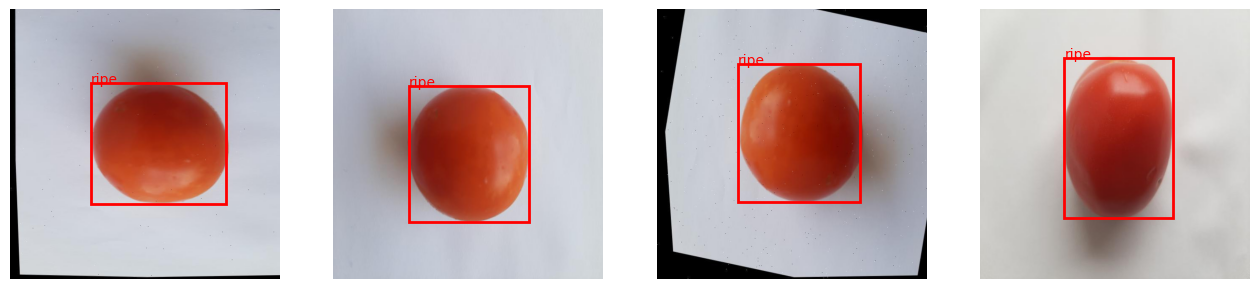

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

pd.DataFrame(audit["class_box_counts"]).T.plot.bar(title="Số bounding box theo lớp / split")
plt.ylabel("Số quả được gán nhãn")
plt.tight_layout()
plt.show()
examples = [row for row in records if row["split"] == "train"][:4]
fig, axes = plt.subplots(1, len(examples), figsize=(16, 4), squeeze=False)
for ax, row in zip(axes.ravel(), examples):
    with Image.open(DATA_ROOT / row["path"]) as original:
        img = original.convert("RGB")
    ax.imshow(img)
    for label, x, y, w, h in row["boxes"]:
        left, top = (x - w/2) * img.width, (y - h/2) * img.height
        color = "red" if label == 0 else "lime"
        ax.add_patch(Rectangle((left, top), w * img.width, h * img.height,
                               fill=False, edgecolor=color, linewidth=2))
        ax.text(left, top, audit["names"][label], color=color)
    ax.axis("off")
plt.show()


## Smoke test: 1 epoch, 16 Train + 16 Validation, không có Test
Tự chọn CUDA và AMP trên GPU; CPU vẫn chạy được. Lần đầu tải YOLO11n pretrained COCO.
Smoke lưu vào thư mục riêng và gắn `smoke_only=true`; tuyệt đối không dùng cho vận hành.


In [6]:
from fruit_training.train import TrainConfig, train, evaluate
from fruit_training.inference import FruitPredictor

smoke_rows = smoke_subset(records, per_split=16, seed=SEED)
smoke_yaml = prepare_dataset(DATA_ROOT, smoke_rows, CODE_ROOT / "data" / f"smoke-{SESSION}")
SMOKE_RUN = train(smoke_yaml, RUNS_ROOT / f"smoke-{SESSION}",
                  config=TrainConfig(epochs=1, imgsz=320, batch=4, workers=0, seed=SEED, smoke=True))
smoke_metrics = evaluate(smoke_yaml, SMOKE_RUN)
display(smoke_metrics)
smoke_example = next(row for row in smoke_rows if row["split"] == "val")
display(FruitPredictor(SMOKE_RUN).predict(DATA_ROOT / smoke_example["path"], source="smoke",
                                         annotated_path=SMOKE_RUN / "example.jpg"))
SMOKE_PASSED = True


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/content/aiot-ml-5aeff8959d22/fruit-health/.runtime/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.203 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aiot-ml-5aeff8959d22/fruit-health/data/smoke-20261015T040727_579719Z/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, ep

{'model_version': 'smoke-20261015T040727_579719Z',
 'split': 'val',
 'evaluated_at': '2026-10-15T04:10:26.289210+00:00',
 'images': 16,
 'mAP50': 0.07136929785022601,
 'mAP50_95': 0.04967653823147611,
 'precision': 0.006568402003902456,
 'recall': 0.9115384615384616,
 'per_class': {'ripe': {'precision': 0.008784773060029283,
   'recall': 0.9230769230769231,
   'mAP50': 0.034951306537184465,
   'mAP50_95': 0.022819073034542774},
  'unripe': {'precision': 0.004352030947775629,
   'recall': 0.9,
   'mAP50': 0.10778728916326756,
   'mAP50_95': 0.07653400342840944}},
 'count_confidence': 0.25,
 'nms_iou': 0.7,
 'count_mae': 2.25,
 'count_rmse': 3.3541019662496847,
 'count_bias': -2.25,
 'class_count_mae': {'ripe': 1.625, 'unripe': 0.625},
 'max_det': 300,
 'precision_recall_note': 'P/R là thống kê tại điểm F1 tốt nhất trên tập đang đánh giá; không dùng để đổi ngưỡng. Count dùng confidence cố định từ artifact.'}

{'model_version': 'smoke-20261015T040727_579719Z',
 'model_source': 'trained',
 'is_mock': False,
 'smoke_only': True,
 'production_ready': False,
 'source': 'smoke',
 'predicted_at': '2026-10-15T04:10:26.475782+00:00',
 'image_width': 640,
 'image_height': 640,
 'count': 0,
 'counts_by_class': {'ripe': 0, 'unripe': 0},
 'detections': [],
 'count_may_be_truncated': False}

## Huấn luyện đầy đủ — chỉ bật sau khi smoke thành công và đã rà soát dữ liệu
Fine-tune toàn bộ YOLO11n 80 epoch tối đa, early stopping 15 epoch, best theo Validation mAP50–95.
Augmentation chỉ Train; hue bằng 0 để hạn chế làm đổi màu độ chín. Không oversample box riêng lẻ.
Ngưỡng đếm mặc định 0,25/NMS IoU 0,7 được lưu cùng model; điều chỉnh chỉ trên Validation trong run mới.
Loss, PR/F1, confusion matrix và đường mAP được Ultralytics xuất trong `yolo/`.
Checkpoint `yolo/weights/last.pt` và `best.pt` ghi mỗi epoch vào RUNS_ROOT trên Drive.

Resume run **bị ngắt giữa chừng**: đặt FULL_RUN về thư mục Drive cũ, RESUME=True và RUN_FULL=True.
Giữ cùng dataset, đường dẫn prepared, config/seed. Sau runtime reset chạy lại bootstrap + audit;
prepared-full được tạo lại ở cùng đường dẫn. Có thể bỏ qua cell smoke vì run cũ đã qua smoke.
Checkpoint của run đã kết thúc bị Ultralytics bỏ optimizer; không resume run hoàn tất.
Ổ đĩa cần đủ dung lượng; epoch đang ghi có thể mất nếu runtime ngắt đột ngột.


In [8]:
RUN_FULL = True
DATA_REVIEWED = True
RESUME = False
FULL_RUN = RUNS_ROOT / f"full-{SESSION}"  # khi resume: thay bằng thư mục run cũ trên Drive
FULL_CONFIG = TrainConfig(epochs=80, imgsz=640, batch=16, workers=2, seed=SEED)
FULL_YAML = Path("/content/aiot-data/fruit-prepared-full/data.yaml")

if RUN_FULL:
    if not DATA_REVIEWED or (not RESUME and not globals().get("SMOKE_PASSED", False)):
        raise RuntimeError("Cần smoke thành công và xác nhận đã rà soát audit")
    if FULL_YAML.exists():
        if verify_prepared(FULL_YAML)["fingerprint"] != manifest_fingerprint(records):
            raise ValueError("Prepared cũ khác audit: chọn đường dẫn prepared mới, không ghi đè")
    else:
        prepare_dataset(DATA_ROOT, records, FULL_YAML.parent)
    if RESUME:
        old = json.loads((FULL_RUN / "run_config.json").read_text(encoding="utf-8"))
        FULL_CONFIG = TrainConfig(**old["config"])
    FULL_RUN = train(FULL_YAML, FULL_RUN, config=FULL_CONFIG, resume=RESUME)
    display(evaluate(FULL_YAML, FULL_RUN))
else:
    print("Chưa chạy training đầy đủ. Rà soát audit rồi chủ động bật RUN_FULL và DATA_REVIEWED.")


New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.203 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/aiot-data/fruit-prepared-full/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.2, hsv_v=0.2, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/aiot-ml-5aeff8959d22/fruit-health/checkpoints/yolo11n.pt, momentum=0.937, 

{'model_version': 'full-20261015T040727_579719Z',
 'split': 'val',
 'evaluated_at': '2026-10-15T04:57:24.986210+00:00',
 'images': 860,
 'mAP50': 0.9384351656179521,
 'mAP50_95': 0.7938359303789225,
 'precision': 0.9393965050552089,
 'recall': 0.8747885017532241,
 'per_class': {'ripe': {'precision': 0.9468616361131947,
   'recall': 0.9109461966604824,
   'mAP50': 0.9617905962527591,
   'mAP50_95': 0.818375940019808},
  'unripe': {'precision': 0.9319313739972231,
   'recall': 0.8386308068459658,
   'mAP50': 0.9150797349831452,
   'mAP50_95': 0.769295920738037}},
 'count_confidence': 0.25,
 'nms_iou': 0.7,
 'count_mae': 0.2895348837209302,
 'count_rmse': 1.3105120604042972,
 'count_bias': 0.08488372093023255,
 'class_count_mae': {'ripe': 0.1325581395348837, 'unripe': 0.1755813953488372},
 'max_det': 300,
 'precision_recall_note': 'P/R là thống kê tại điểm F1 tốt nhất trên tập đang đánh giá; không dùng để đổi ngưỡng. Count dùng confidence cố định từ artifact.'}

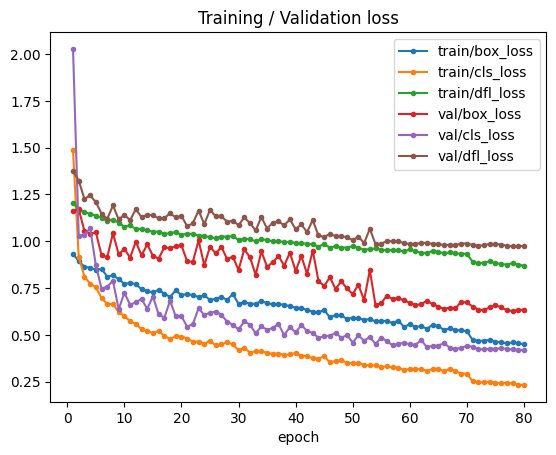

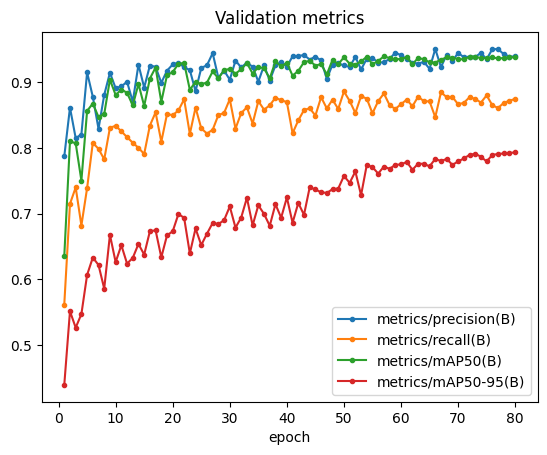

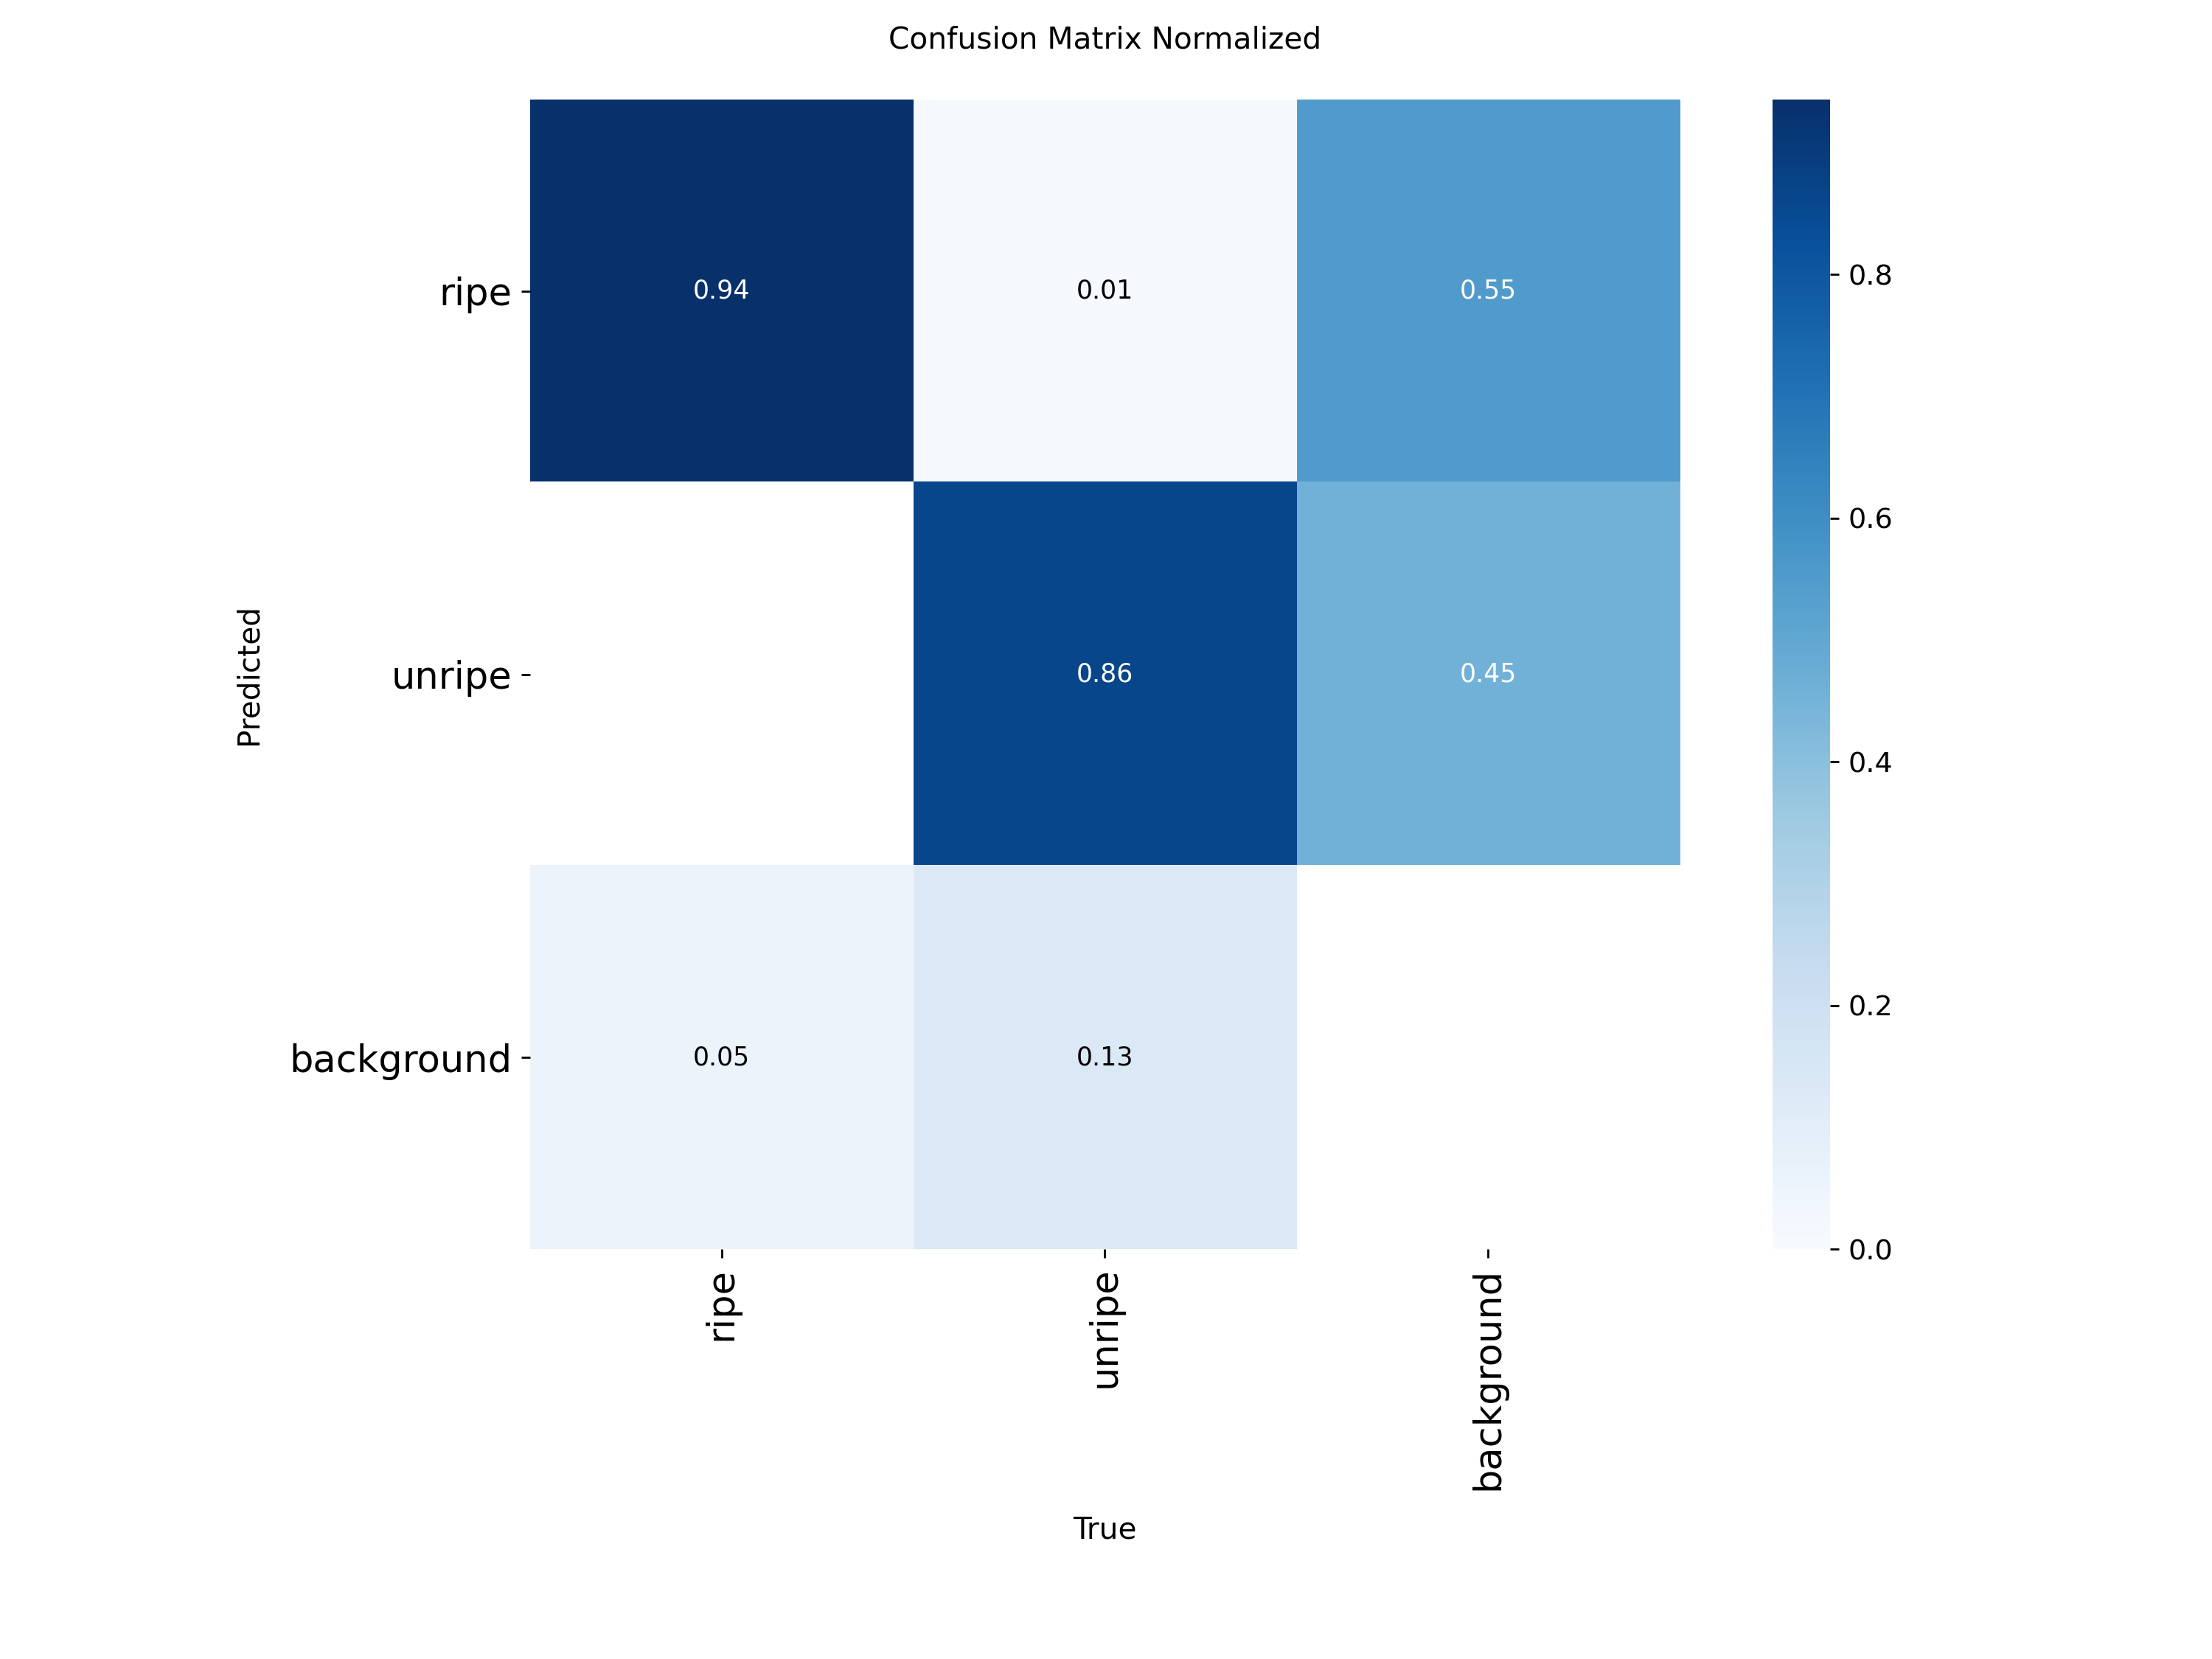

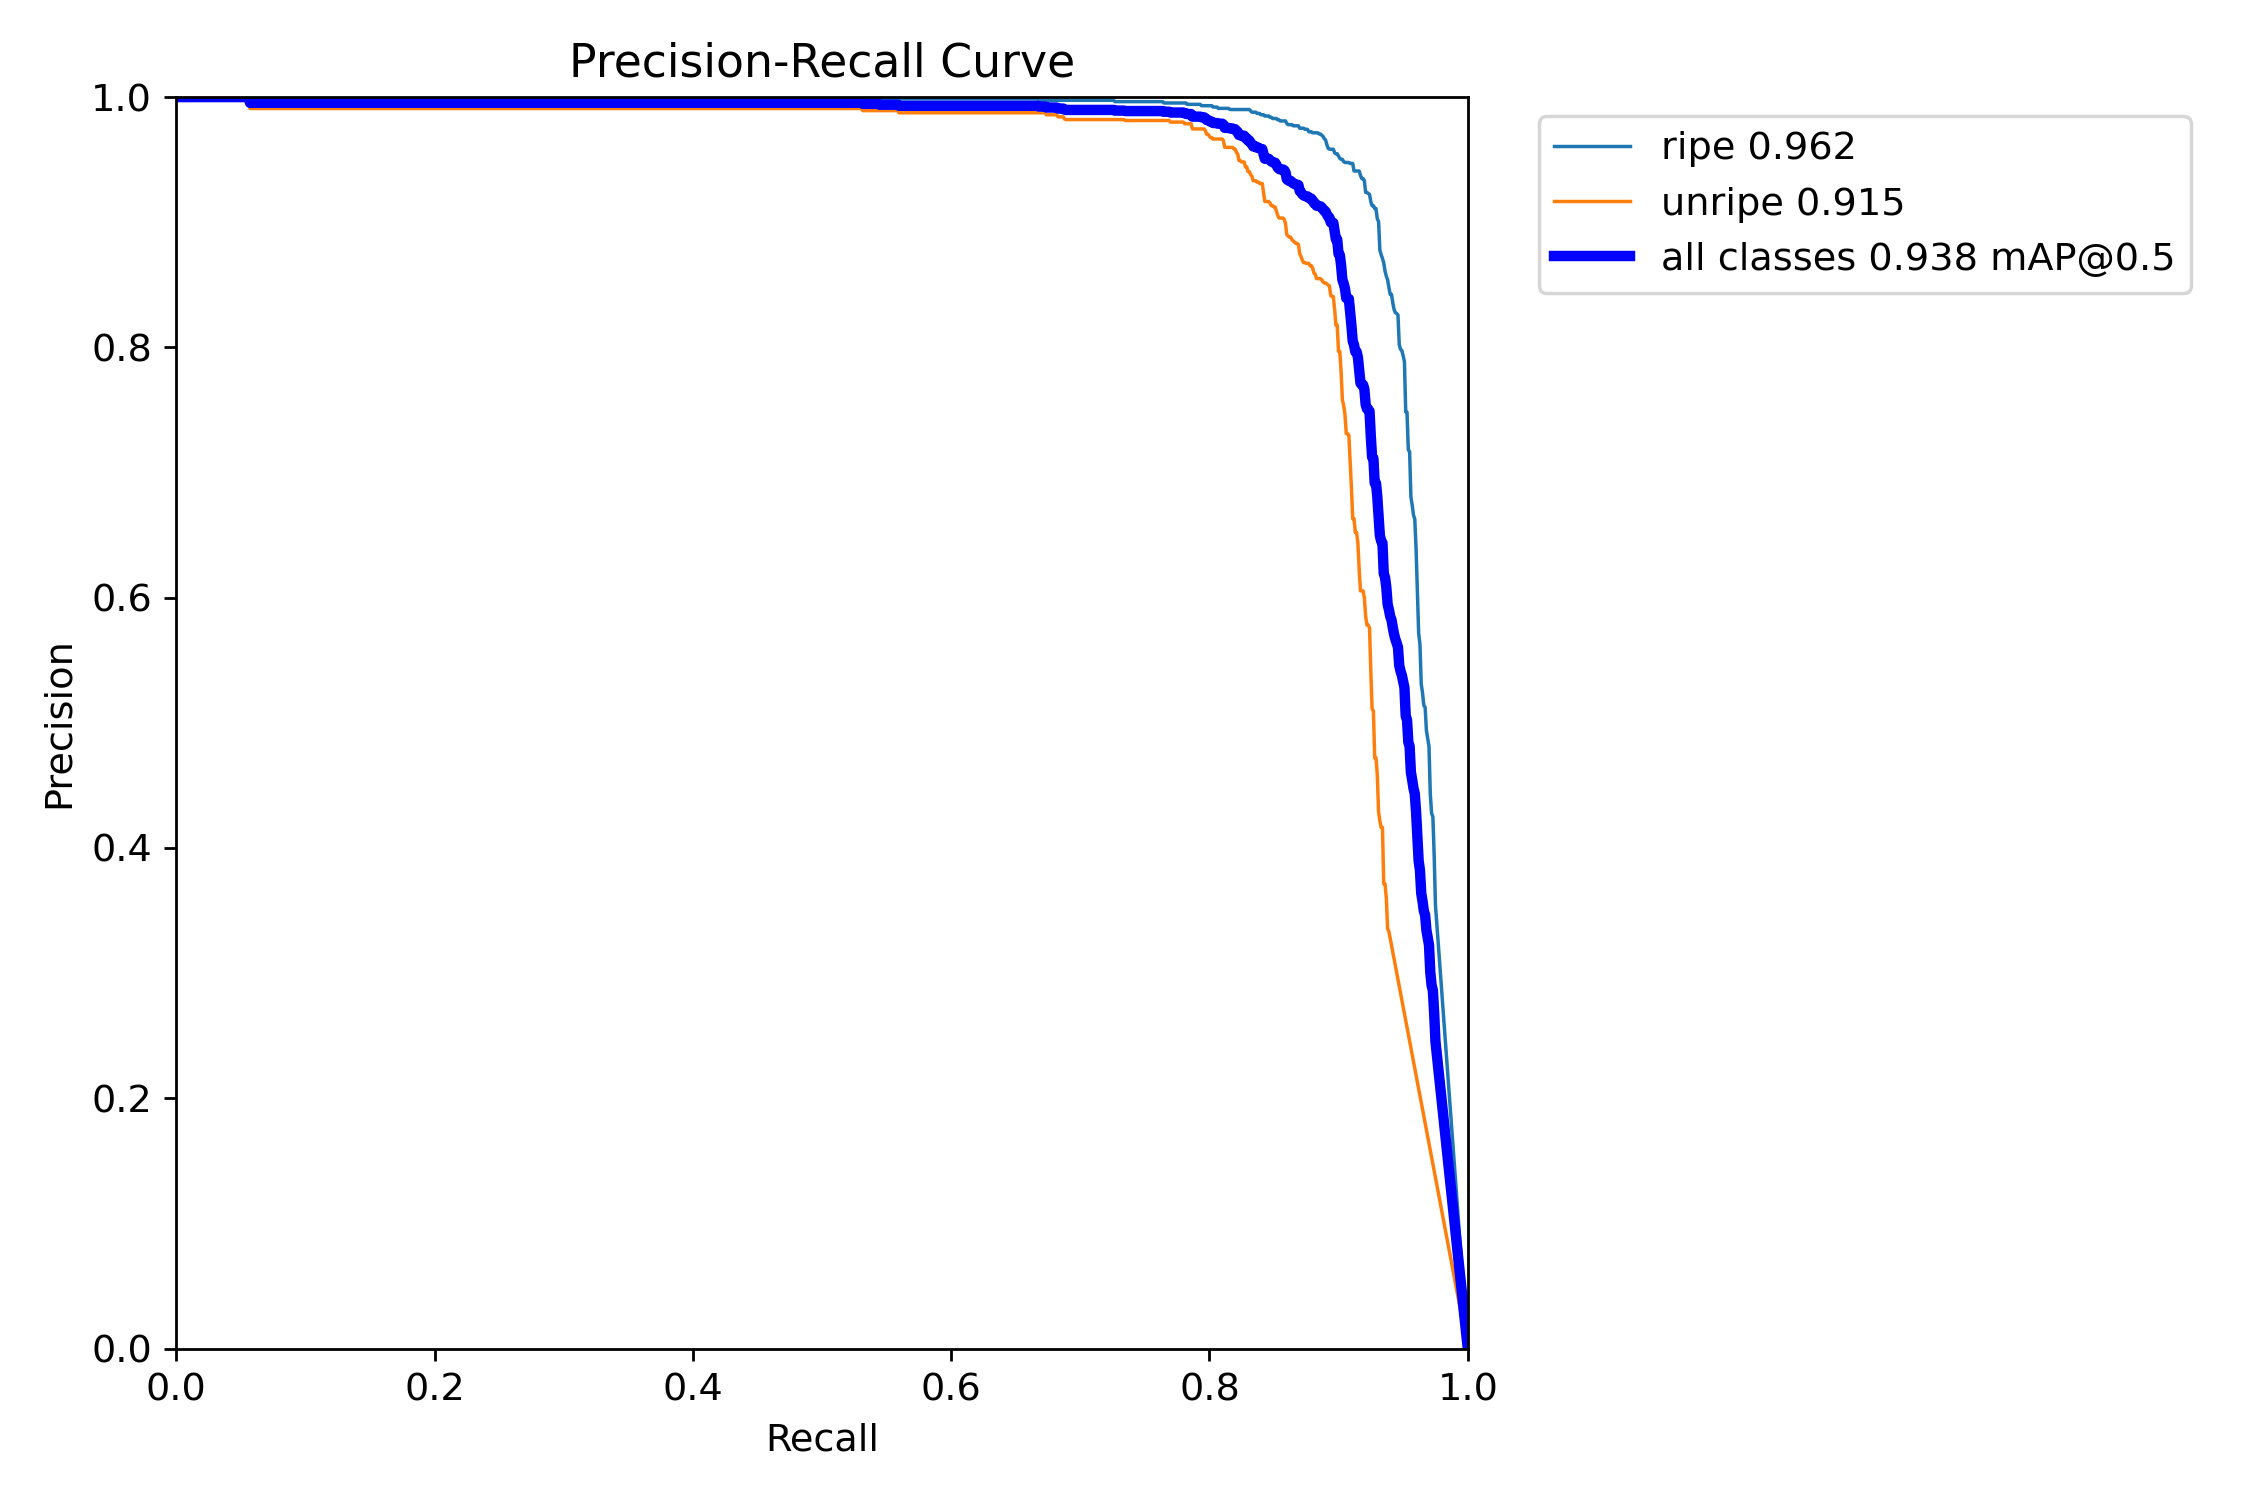

In [9]:
from IPython.display import display, Image as DisplayImage

ARTIFACT = FULL_RUN if RUN_FULL and (FULL_RUN / "metadata.json").exists() else globals().get("SMOKE_RUN")
if ARTIFACT is not None:
    history = pd.read_csv(ARTIFACT / "yolo" / "results.csv")
    history.columns = history.columns.str.strip()
    loss_columns = [name for name in history if name.endswith("_loss")]
    history.plot(x="epoch", y=loss_columns, marker=".", title="Training / Validation loss")
    plt.show()
    metric_columns = [name for name in history if "metrics/" in name]
    history.plot(x="epoch", y=metric_columns, marker=".", title="Validation metrics")
    plt.show()
    for name in ("confusion_matrix_normalized.png", "BoxPR_curve.png"):
        path = ARTIFACT / "evaluation" / "val" / name
        if path.exists():
            display(DisplayImage(filename=str(path), width=700))


## Test cuối cùng
Chỉ mở sau khi chốt kiến trúc, epoch, preprocessing và ngưỡng bằng Validation.
Không huấn luyện/tối ưu theo Test. Bộ test Roboflow vẫn có khác biệt so với ảnh ESP32-CAM;
cần tập camera thật riêng theo cảnh/cây để kết luận khả năng triển khai.
Mỗi artifact chỉ ghi một báo cáo Test; cell chạy lại sẽ đọc báo cáo sẵn có.


In [8]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    if not (FULL_RUN / "metadata.json").exists():
        raise RuntimeError("Cần model đầy đủ đã hoàn tất; không dùng smoke cho Test")
    report_path = FULL_RUN / "test_metrics.json"
    if report_path.exists():
        display(json.loads(report_path.read_text(encoding="utf-8")))
    else:
        display(evaluate(FULL_YAML, FULL_RUN, split="test", allow_test=True))
else:
    print("Test đang khóa.")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/content/aiot-ml-5aeff8959d22/fruit-health/.runtime/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.203 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,542 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1158.1±583.1 MB/s, size: 35.0 KB)
val: Scanning /content/aiot-data/fruit-prepared-full/test/labels... 1254 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1254/1254 2.1Kit/s 0.6s0.1s
val: New cache created: /content/aiot-data/fruit-prepared-full/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 314/314 17.9it/s 17.6s0.1s
                   all       12

{'model_version': 'full-20261015T040727_579719Z',
 'split': 'test',
 'evaluated_at': '2026-10-15T10:40:45.073400+00:00',
 'images': 1254,
 'mAP50': 0.9287094118580556,
 'mAP50_95': 0.7673929470860636,
 'precision': 0.9373591133864805,
 'recall': 0.8619864817739546,
 'per_class': {'ripe': {'precision': 0.9338542434384431,
   'recall': 0.9083532355775789,
   'mAP50': 0.959094068329648,
   'mAP50_95': 0.802164387944696},
  'unripe': {'precision': 0.9408639833345178,
   'recall': 0.8156197279703304,
   'mAP50': 0.8983247553864631,
   'mAP50_95': 0.7326215062274313}},
 'count_confidence': 0.25,
 'nms_iou': 0.7,
 'count_mae': 0.3317384370015949,
 'count_rmse': 1.3209150566640726,
 'count_bias': -0.02073365231259968,
 'class_count_mae': {'ripe': 0.13476874003189793,
  'unripe': 0.23365231259968103},
 'max_det': 300,
 'precision_recall_note': 'P/R là thống kê tại điểm F1 tốt nhất trên tập đang đánh giá; không dùng để đổi ngưỡng. Count dùng confidence cố định từ artifact.'}

## Inference ảnh mới và bàn giao artifact
Đặt NEW_IMAGE tới ảnh trong Google Drive. Output gồm bbox pixel + chuẩn hóa, confidence,
ripe/unripe, số quả từng lớp, version và thời điểm UTC. Đây là đếm từng ảnh, không tracking.
Artifact cần chuyển cùng nhau: `best.pt`, `metadata.json`, `class_mapping.json`, `preprocessing.json`.
Chỉ load checkpoint tin cậy. Chưa nối vào backend Mock AI và chưa điều khiển bơm.


{'model_version': 'full-20261015T040727_579719Z',
 'model_source': 'trained',
 'is_mock': False,
 'smoke_only': False,
 'production_ready': False,
 'source': 'manual',
 'predicted_at': '2026-10-15T10:50:27.335825+00:00',
 'image_width': 1920,
 'image_height': 1368,
 'count': 3,
 'counts_by_class': {'ripe': 1, 'unripe': 2},
 'detections': [{'class_id': 0,
   'label': 'ripe',
   'confidence': 0.9444572329521179,
   'bbox_xyxy': [46.948974609375,
    585.0408325195312,
    905.4472045898438,
    1350.655029296875],
   'bbox_xyxy_normalized': [0.024452591314911842,
    0.4276614189147949,
    0.4715871214866638,
    0.9873209595680237]},
  {'class_id': 1,
   'label': 'unripe',
   'confidence': 0.9275906085968018,
   'bbox_xyxy': [635.4888916015625,
    317.39703369140625,
    1210.74072265625,
    878.1384887695312],
   'bbox_xyxy_normalized': [0.33098381757736206,
    0.23201537132263184,
    0.6305941343307495,
    0.6419141292572021]},
  {'class_id': 1,
   'label': 'unripe',
   'confide

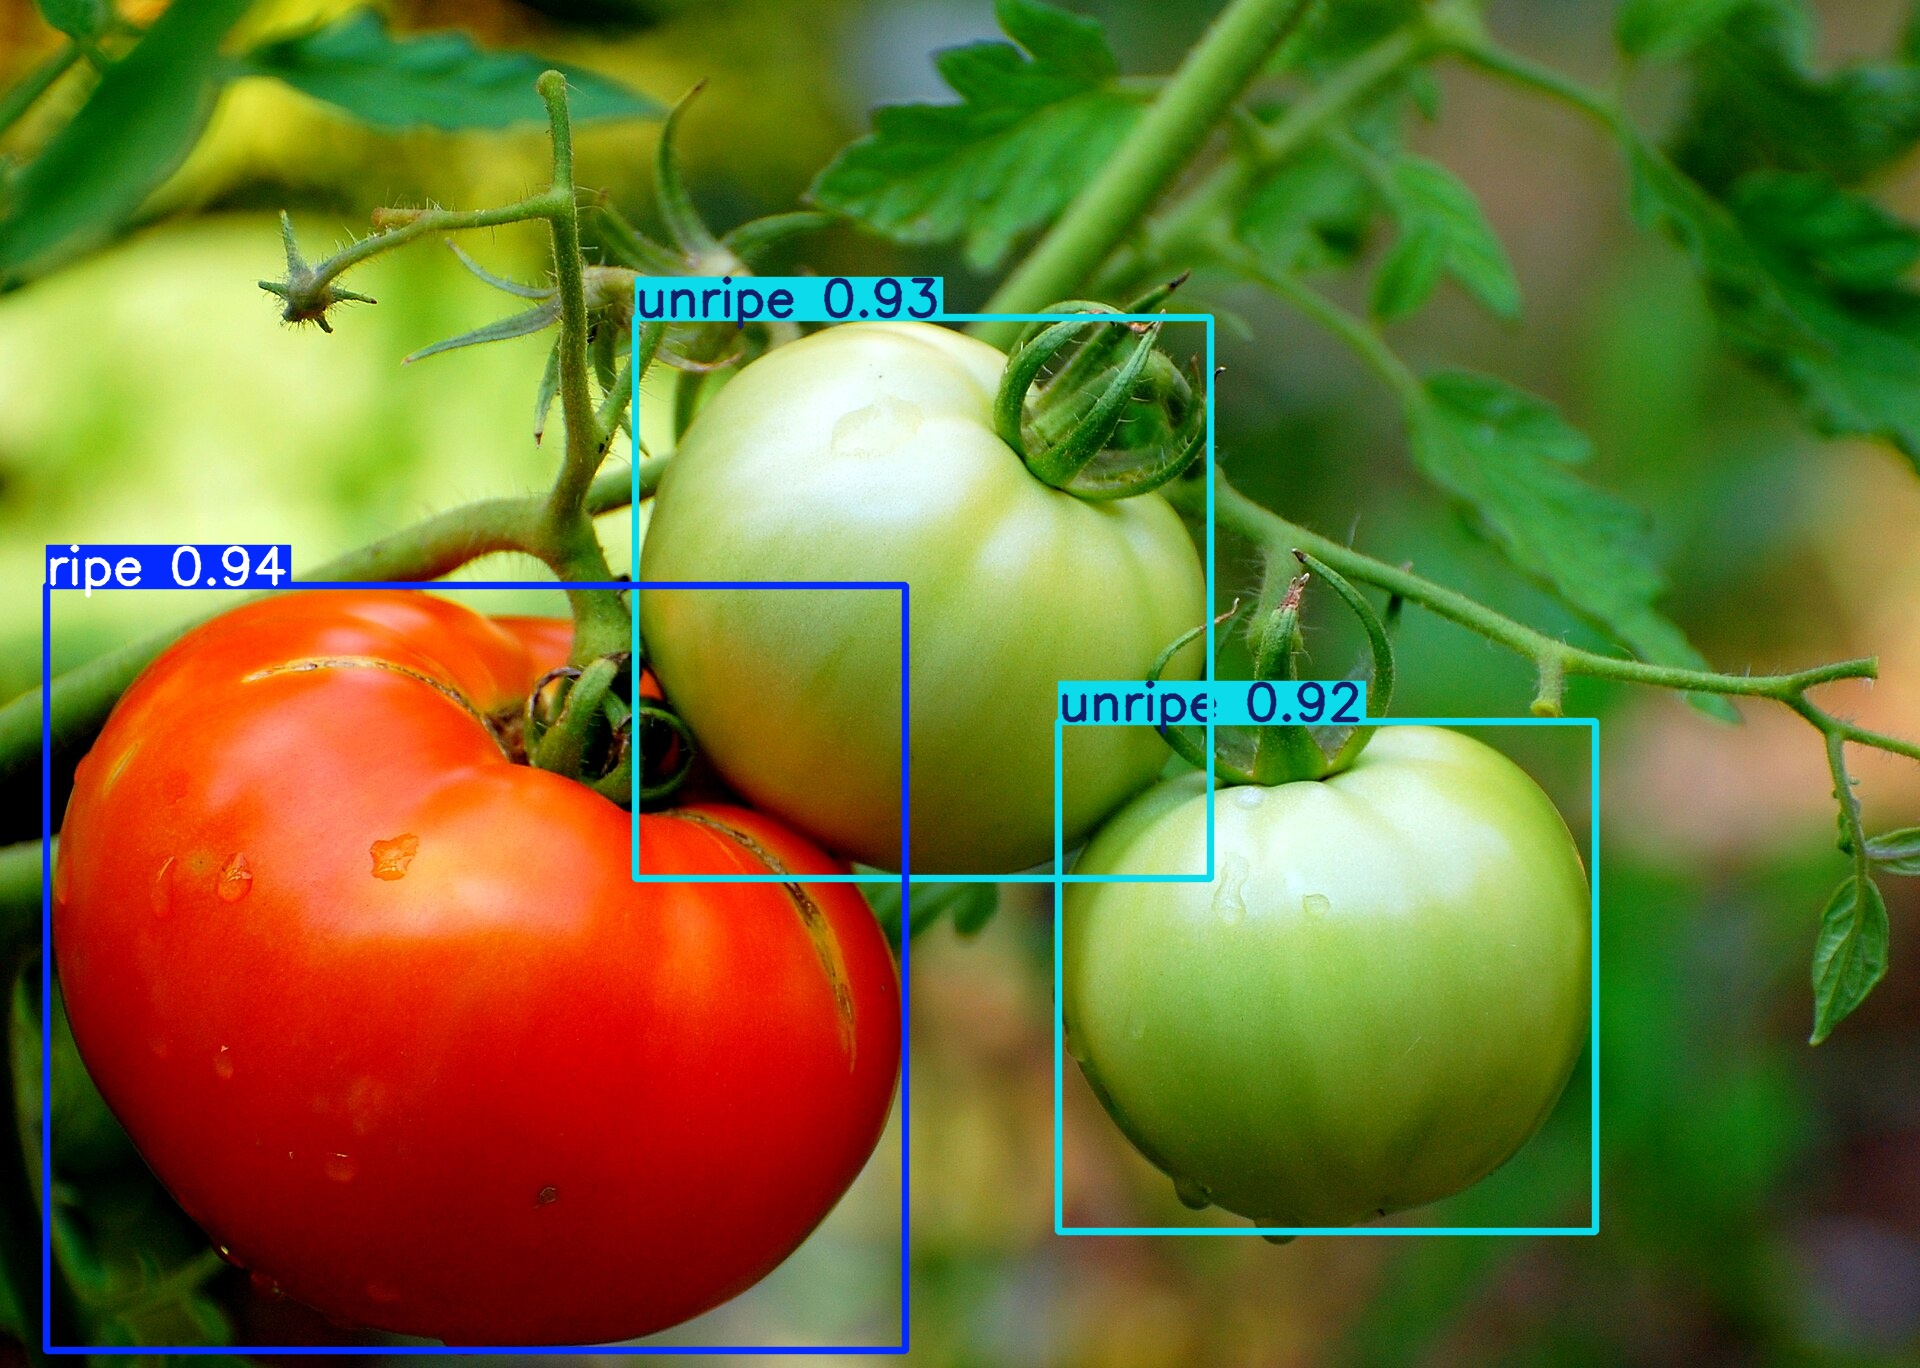

In [11]:
from pathlib import Path
from IPython.display import display, Image as DisplayImage
from fruit_training.inference import FruitPredictor

NEW_IMAGE = Path(
    "/content/drive/MyDrive/aiot-plant-care/tomato-camera.jpg"
)

ARTIFACT = Path(
    "/content/drive/MyDrive/aiot-plant-care/fruit-runs/"
    "full-20261015T040727_579719Z"
)

assert NEW_IMAGE.is_file(), f"Không tìm thấy ảnh: {NEW_IMAGE}"
assert (ARTIFACT / "yolo/weights/best.pt").is_file(), "Không tìm thấy model"

predictor = FruitPredictor(ARTIFACT)

annotated = ARTIFACT / "inference-tomato.jpg"

result = predictor.predict(
    NEW_IMAGE,
    source="manual",
    annotated_path=annotated
)

display(result)
display(DisplayImage(filename=str(annotated), width=700))